# Diabetes Health Indicators Dataset (BRFSS 2015)

This dataset is based on the CDC's 2015 BRFSS survey and contains health-related features for over 250,000 individuals. It is used to predict diabetes risk, with both multi-class and binary target variables. The data supports early detection and prevention efforts for diabetes.

**About the Dataset:**
- The BRFSS is a large annual health survey by the CDC, collecting data on health behaviors and conditions from over 400,000 Americans.
- The 2015 dataset used here includes 21 health-related features and several target variables for diabetes prediction.

**Files included:**
- `diabetes_012_health_indicators_BRFSS2015.csv`: 3-class target (no diabetes, prediabetes, diabetes), imbalanced, 253,680 samples.
- `diabetes_binary_5050split_health_indicators_BRFSS2015.csv`: 2-class target (no diabetes, prediabetes/diabetes), balanced, 70,692 samples.
- `diabetes_binary_health_indicators_BRFSS2015.csv`: 2-class target (no diabetes, prediabetes/diabetes), imbalanced, 253,680 samples.

In [1]:
# Install required packages (uncomment to run)
%pip install matplotlib pandas numpy seaborn scikit-learn imblearn

  Using cached imblearn-0.0-py2.py3-none-any.whl.metadata (355 bytes)
  Using cached imbalanced_learn-0.14.1-py3-none-any.whl.metadata (8.9 kB)
  Using cached sklearn_compat-0.1.5-py3-none-any.whl.metadata (20 kB)
Using cached imblearn-0.0-py2.py3-none-any.whl (1.9 kB)
Using cached imbalanced_learn-0.14.1-py3-none-any.whl (235 kB)
Using cached sklearn_compat-0.1.5-py3-none-any.whl (20 kB)

   ---------------------------------------- 0/3 [sklearn-compat]
   ---------------------------------------- 0/3 [sklearn-compat]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   -----


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import Required Libraries

In [2]:
# Import necessary libraries
import numpy as np  # For numerical operations
import pandas as pd  # For data manipulation and analysis
import matplotlib.pyplot as plt  # For creating visualizations
import seaborn as sns  # For statistical data visualization
import warnings

# Configure display settings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

## Load the Dataset

Loading the diabetes health indicators dataset from BRFSS 2015 survey.

In [3]:
# Load Dataset 6 files
DATA_PATHS = [
    "./data/raw/6_cdc_diabetes_health_indicators.csv",
    "./data/raw/Dataset_6/diabetes_binary_5050split_health_indicators_BRFSS2015.csv",
    "./data/raw/Dataset_6/diabetes_binary_health_indicators_BRFSS2015.csv"
]

df_012 = pd.read_csv(DATA_PATHS[0])
df_binary_5050 = pd.read_csv(DATA_PATHS[1]) 
df_binary = pd.read_csv(DATA_PATHS[2])

# Display basic info
print(f"Dataset 1 (012) Shape: {df_012.shape}")
print(f"Dataset 2 (Binary 50/50) Shape: {df_binary_5050.shape}")
print(f"Dataset 3 (Binary) Shape: {df_binary.shape}")
df_binary.head()


Dataset 1 (012) Shape: (253680, 22)
Dataset 2 (Binary 50/50) Shape: (70692, 22)
Dataset 3 (Binary) Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## Data Exploration

Understanding the structure, types, and basic statistics of the dataset.

In [4]:
# Dataset info
df_binary.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [5]:
# Statistical summary of the dataset
df_binary.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [6]:
# Unique value counts
unique_values = {col: df_binary[col].nunique() for col in df_binary.columns}
pd.DataFrame(unique_values, index=['Unique Value Count']).T


,Unique Value Count
Diabetes_binary,2
HighBP,2
HighChol,2
CholCheck,2
BMI,84
Smoker,2
Stroke,2
HeartDiseaseorAttack,2
PhysActivity,2
Fruits,2


### Check for Missing Values

Identifying any null values in the dataset that need to be handled.

In [7]:
# Check for missing values
missing_values = df_binary.isnull().sum()
print(f"Total missing values: {missing_values.sum()}")


Total missing values: 0


### Check for Duplicate Rows

Identifying and removing duplicate entries to ensure data quality.

In [8]:
# Check for duplicates
duplicated_rows = df_binary[df_binary.duplicated()]
print(f"Duplicated rows: {duplicated_rows.shape[0]} ({(duplicated_rows.shape[0]/len(df_binary))*100:.2f}%)")


Duplicated rows: 24206 (9.54%)


In [9]:
# Remove duplicates
df_binary.drop_duplicates(inplace=True)
print(f"Shape after removing duplicates: {df_binary.shape}")


Shape after removing duplicates: (229474, 22)


In [10]:
# Verify duplicates removed
print(f"Remaining duplicates: {df_binary[df_binary.duplicated()].shape[0]}")


Remaining duplicates: 0


## Exploratory Data Analysis (EDA)

Visualizing and analyzing the data to understand patterns, relationships, and distributions.

### Target Variable Distribution

Analyzing the distribution of the target variable (Diabetes_binary) to understand class balance.

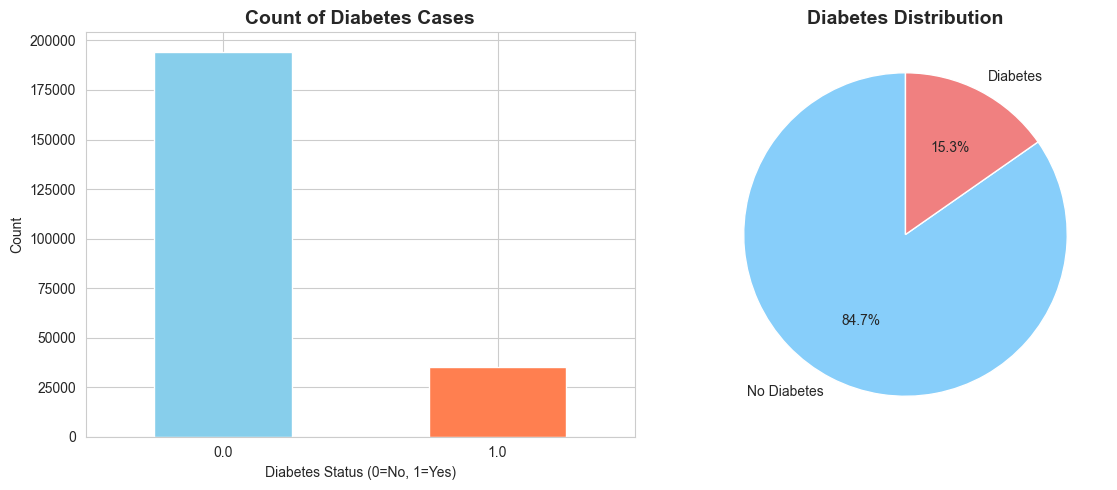

In [11]:
# Target variable distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
df_binary['Diabetes_binary'].value_counts().plot(kind='bar', color=['skyblue', 'coral'])
plt.title('Count of Diabetes Cases', fontsize=14, fontweight='bold')
plt.xlabel('Diabetes Status (0=No, 1=Yes)')
plt.ylabel('Count')
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
labels = ['No Diabetes', 'Diabetes']
sizes = df_binary['Diabetes_binary'].value_counts()
colors = ['lightskyblue', 'lightcoral']
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90)
plt.title('Diabetes Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


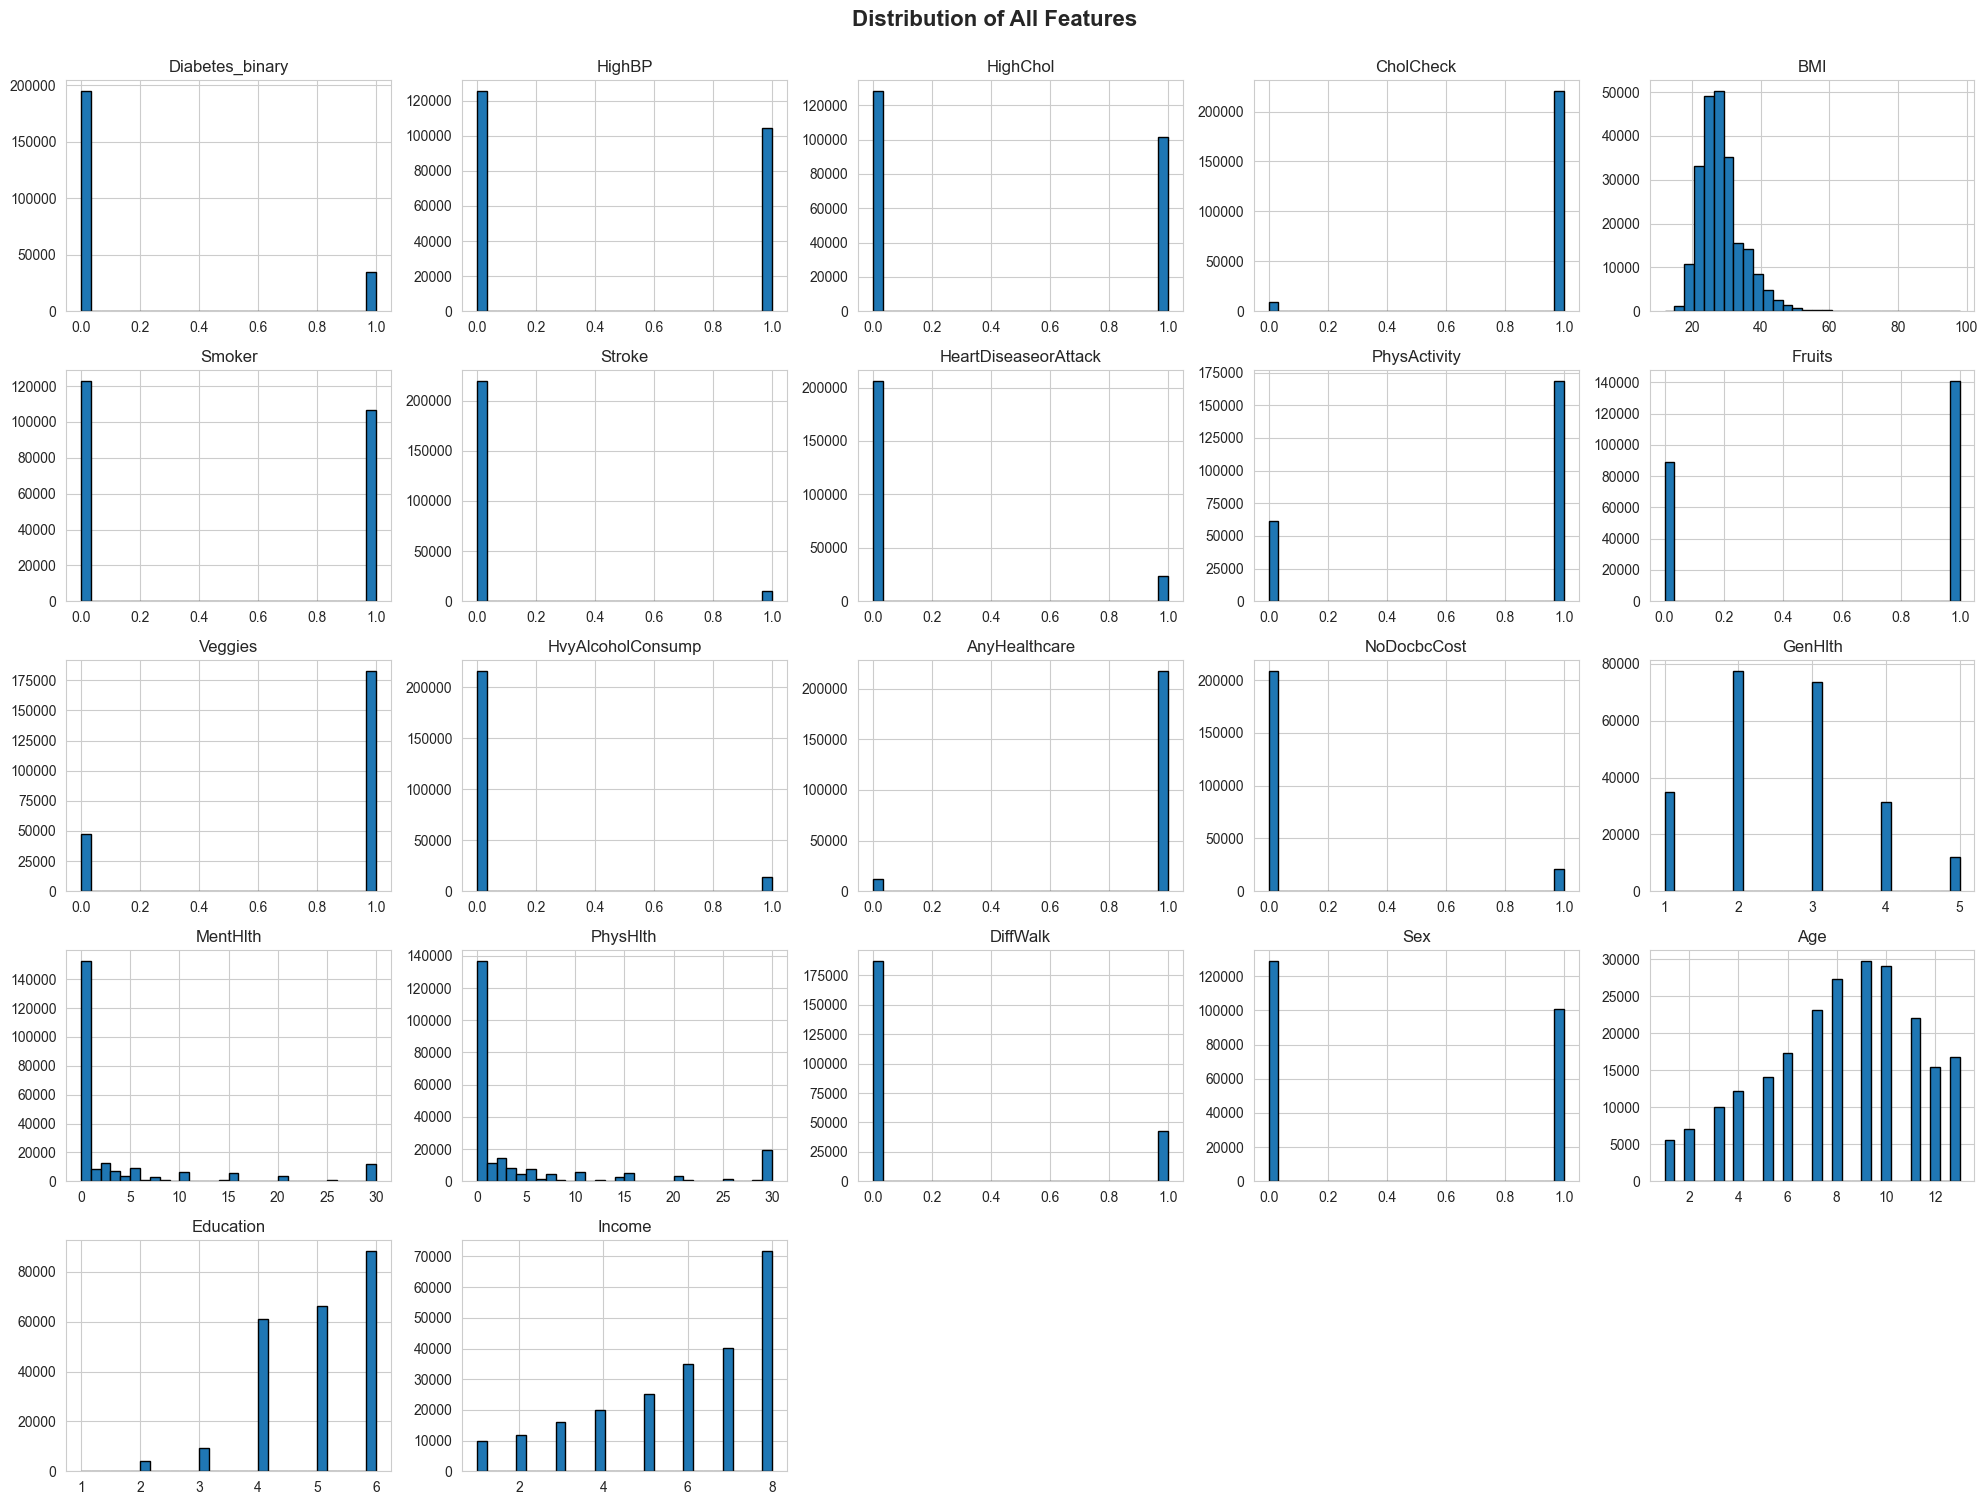

In [12]:
# Histograms for all features
df_binary.hist(figsize=(20, 15), bins=30, edgecolor='black')
plt.suptitle('Distribution of All Features', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### Feature Distributions

Visualizing the distribution of all features to understand their spread and patterns.

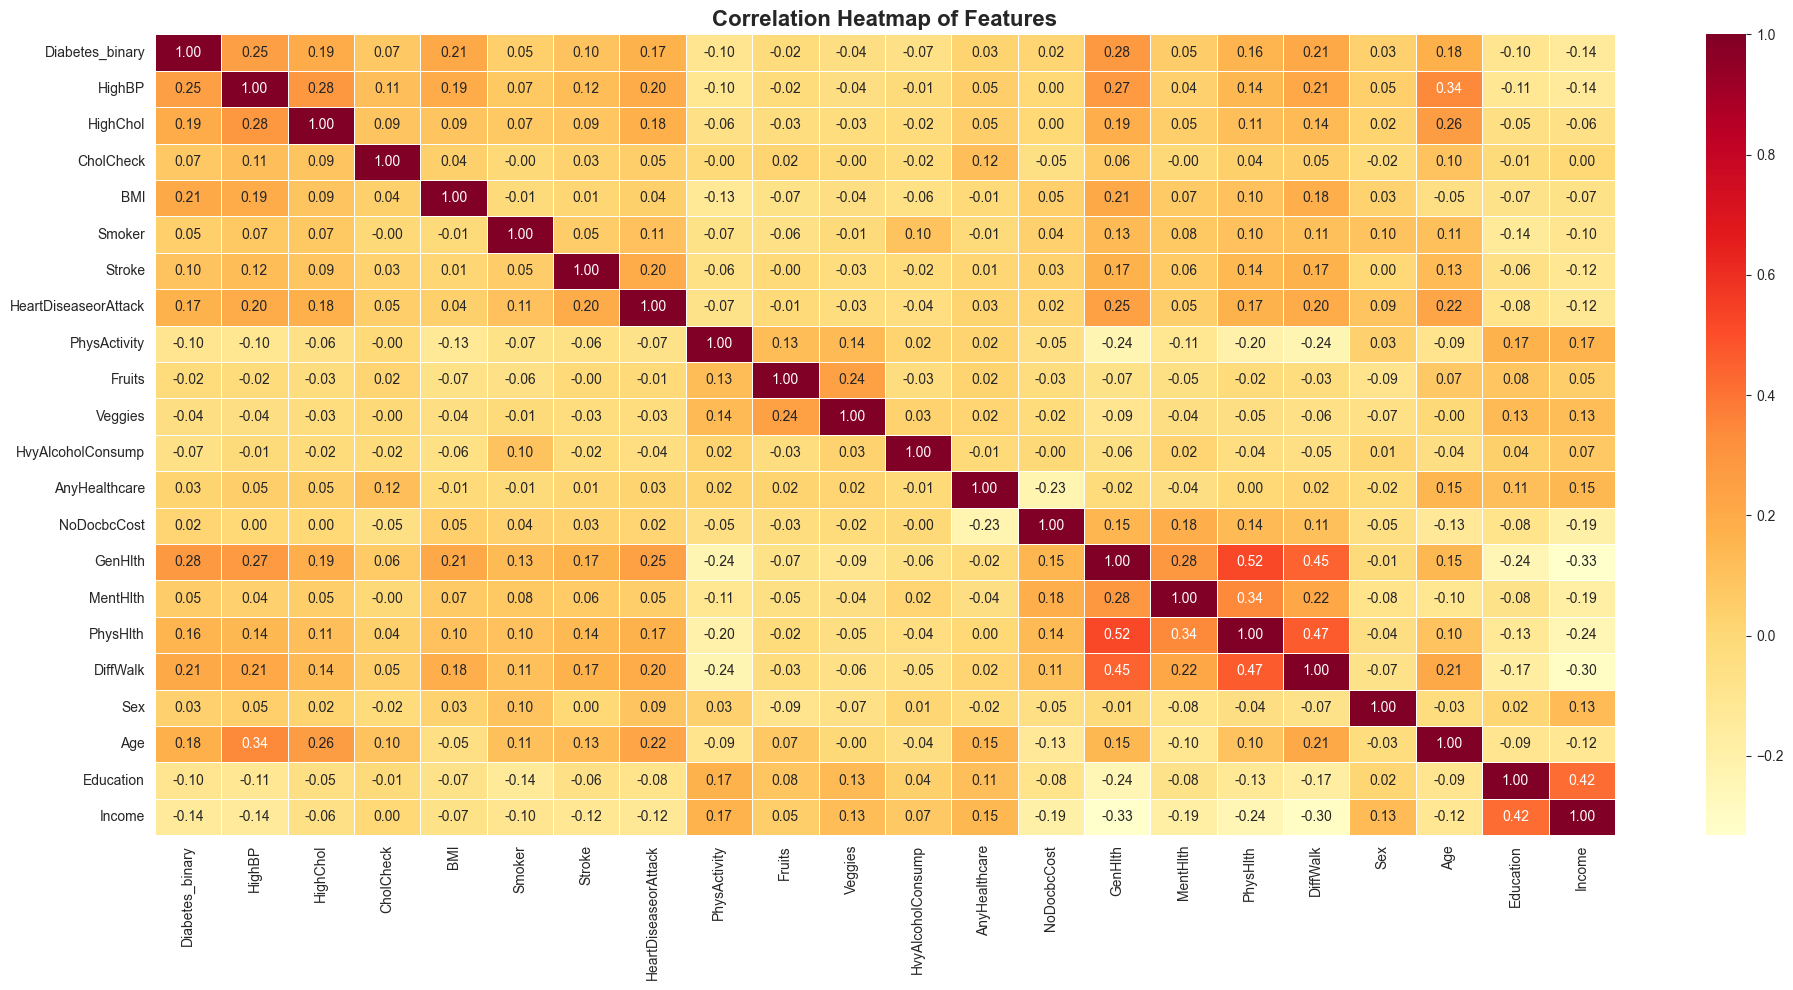

In [13]:
# Correlation heatmap
plt.figure(figsize=(20, 10))
sns.heatmap(df_binary.corr(), annot=True, cmap='YlOrRd', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### Correlation Analysis

Examining correlations between features to identify multicollinearity and relationships with the target variable.

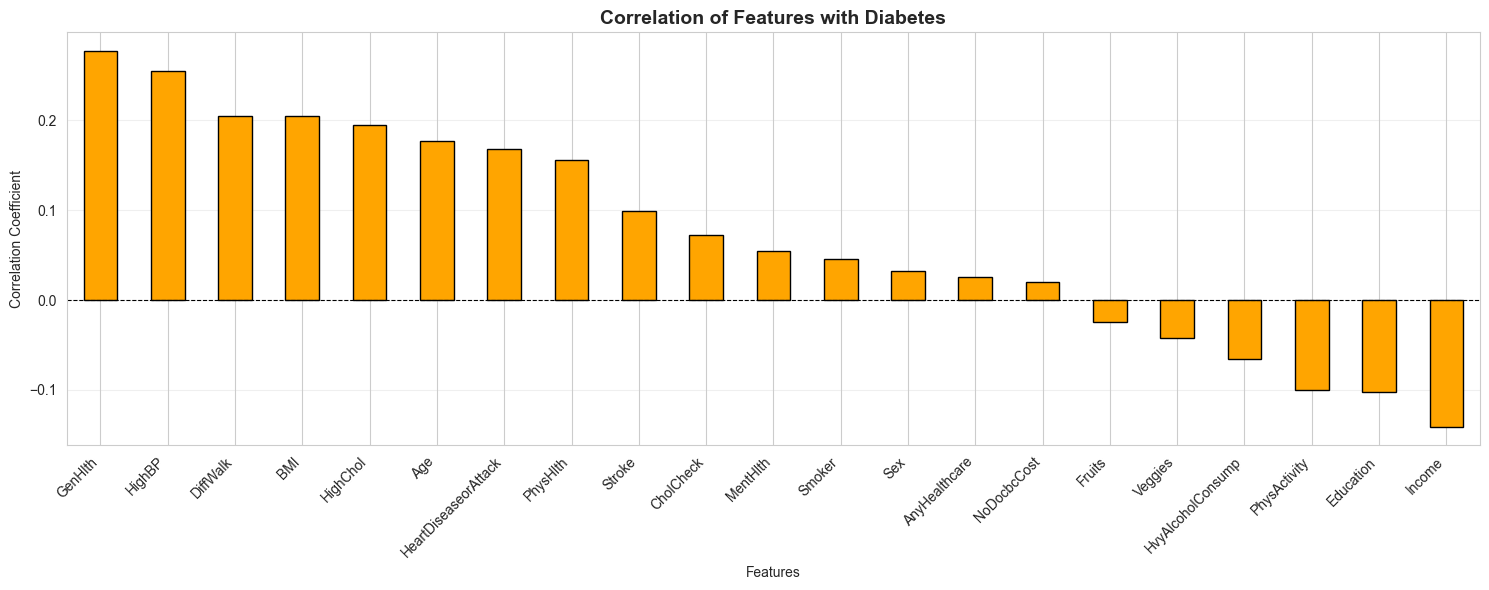

In [14]:
# Correlation with target variable
plt.figure(figsize=(15, 6))
correlation_with_target = df_binary.drop('Diabetes_binary', axis=1).corrwith(df_binary['Diabetes_binary']).sort_values(ascending=False)
correlation_with_target.plot(kind='bar', color='orange', edgecolor='black')
plt.title('Correlation of Features with Diabetes', fontsize=14, fontweight='bold')
plt.xlabel('Features')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=45, ha='right')
plt.axhline(y=0, color='black', linestyle='--', linewidth=0.8)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Key Findings from Correlation Analysis

**Least Correlated Features:**
- Fruits, AnyHealthcare, NoDocbcCost, and Sex show minimal correlation with Diabetes_binary

**Most Correlated Features:**
- HighBP, HighChol, GenHlth, BMI, Age, DiffWalk, HeartDiseaseorAttack, PhysHlth, Income, and Stroke show significant positive correlation with Diabetes_binary
- These features are important indicators for diabetes prediction

### Analyzing Key Risk Factors

Examining the relationship between major health indicators and diabetes.

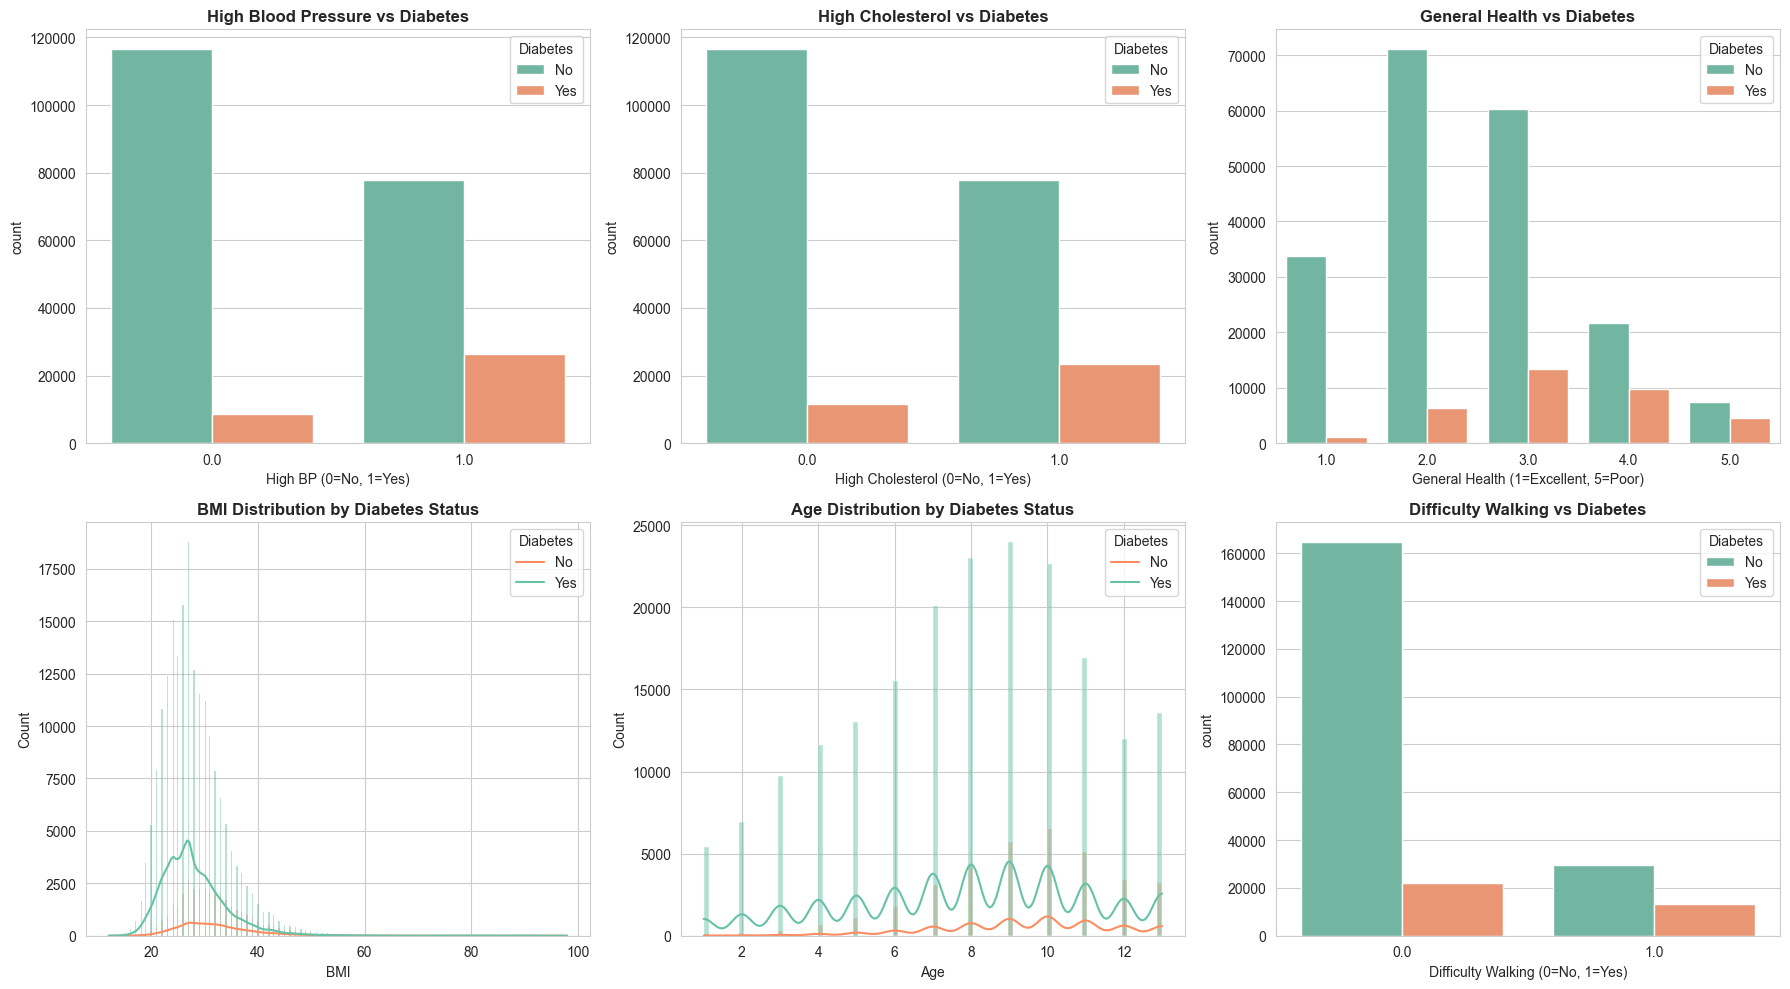

In [15]:
# Analyzing major risk factors
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# HighBP
sns.countplot(x='HighBP', hue='Diabetes_binary', data=df_binary, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('High Blood Pressure vs Diabetes', fontweight='bold')
axes[0, 0].set_xlabel('High BP (0=No, 1=Yes)')
axes[0, 0].legend(title='Diabetes', labels=['No', 'Yes'])

# HighChol
sns.countplot(x='HighChol', hue='Diabetes_binary', data=df_binary, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('High Cholesterol vs Diabetes', fontweight='bold')
axes[0, 1].set_xlabel('High Cholesterol (0=No, 1=Yes)')
axes[0, 1].legend(title='Diabetes', labels=['No', 'Yes'])

# GenHlth
sns.countplot(x='GenHlth', hue='Diabetes_binary', data=df_binary, ax=axes[0, 2], palette='Set2')
axes[0, 2].set_title('General Health vs Diabetes', fontweight='bold')
axes[0, 2].set_xlabel('General Health (1=Excellent, 5=Poor)')
axes[0, 2].legend(title='Diabetes', labels=['No', 'Yes'])

# BMI Distribution
sns.histplot(data=df_binary, x='BMI', hue='Diabetes_binary', kde=True, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('BMI Distribution by Diabetes Status', fontweight='bold')
axes[1, 0].legend(title='Diabetes', labels=['No', 'Yes'])

# Age Distribution
sns.histplot(data=df_binary, x='Age', hue='Diabetes_binary', kde=True, ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Age Distribution by Diabetes Status', fontweight='bold')
axes[1, 1].legend(title='Diabetes', labels=['No', 'Yes'])

# DiffWalk
sns.countplot(x='DiffWalk', hue='Diabetes_binary', data=df_binary, ax=axes[1, 2], palette='Set2')
axes[1, 2].set_title('Difficulty Walking vs Diabetes', fontweight='bold')
axes[1, 2].set_xlabel('Difficulty Walking (0=No, 1=Yes)')
axes[1, 2].legend(title='Diabetes', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()

### Outlier Detection

Using boxplots to identify outliers in continuous features.

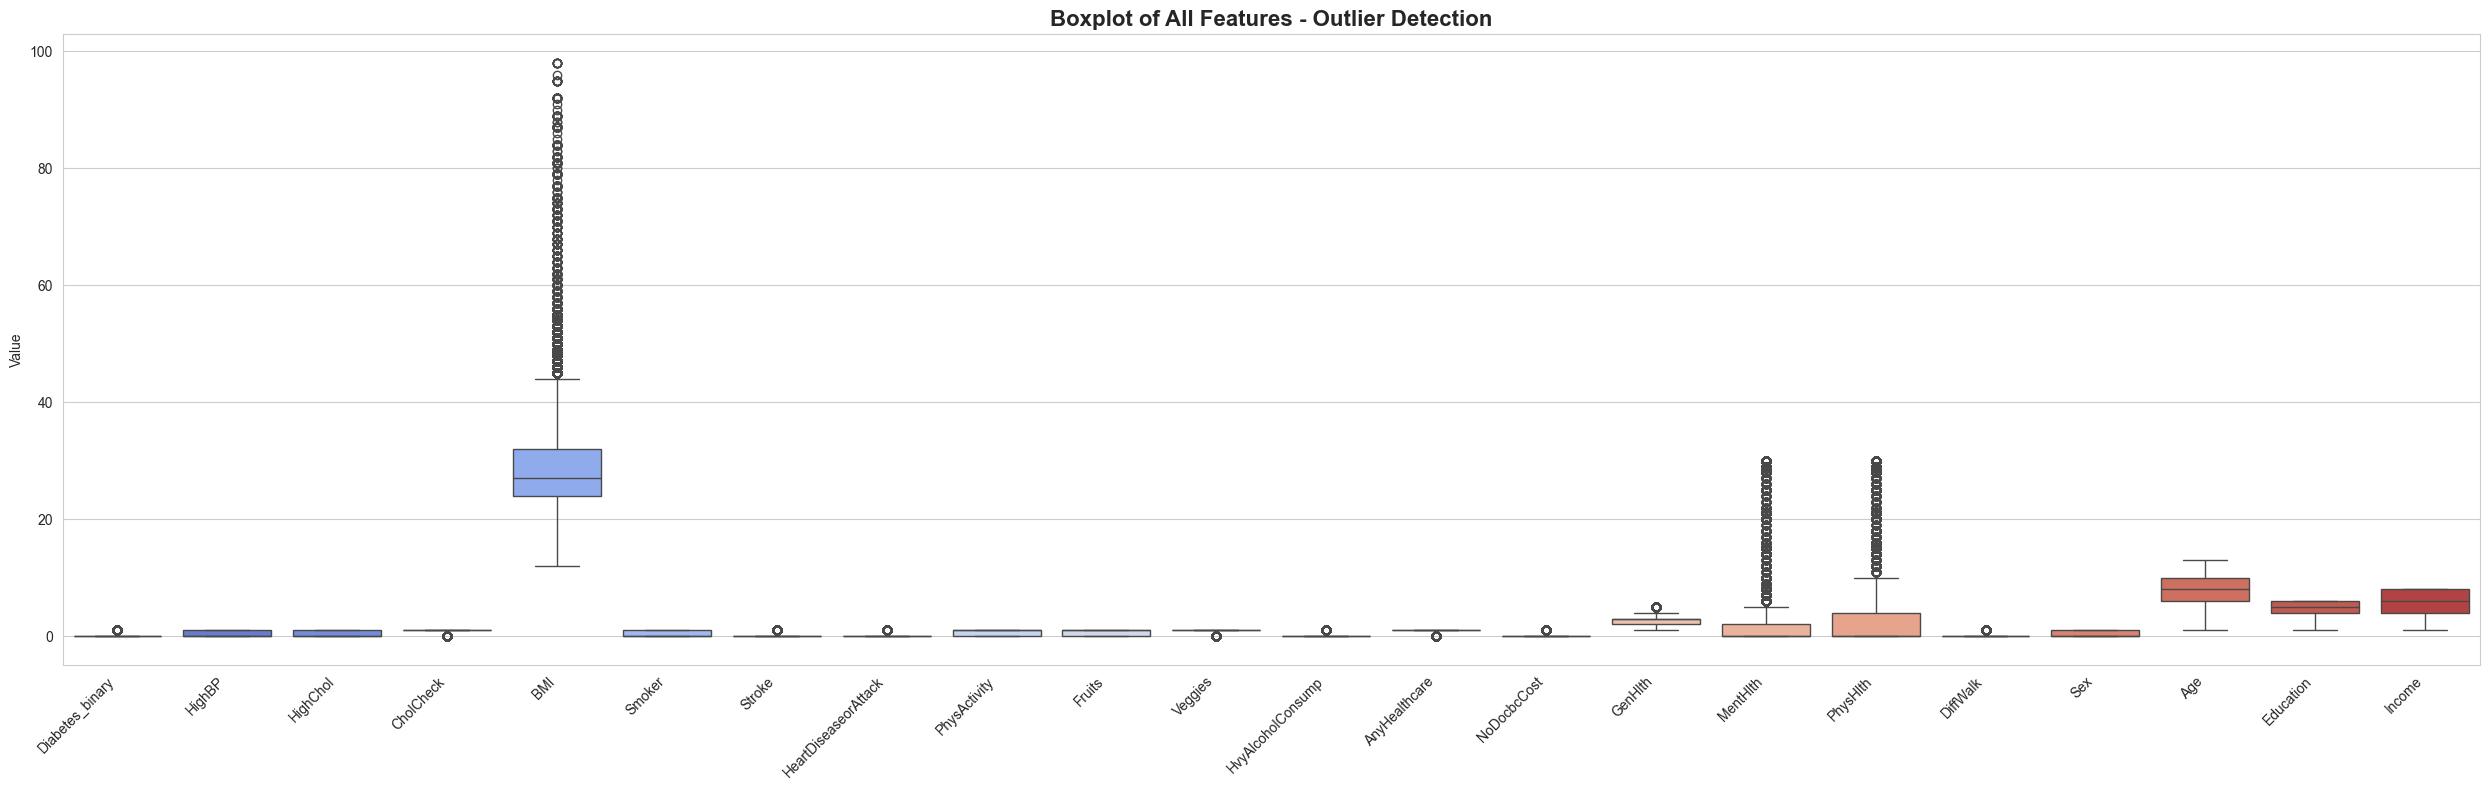

In [16]:
# Boxplot for all features to detect outliers
plt.figure(figsize=(25, 8))
sns.boxplot(data=df_binary, palette='coolwarm')
plt.title('Boxplot of All Features - Outlier Detection', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Value')
plt.tight_layout()
plt.show()

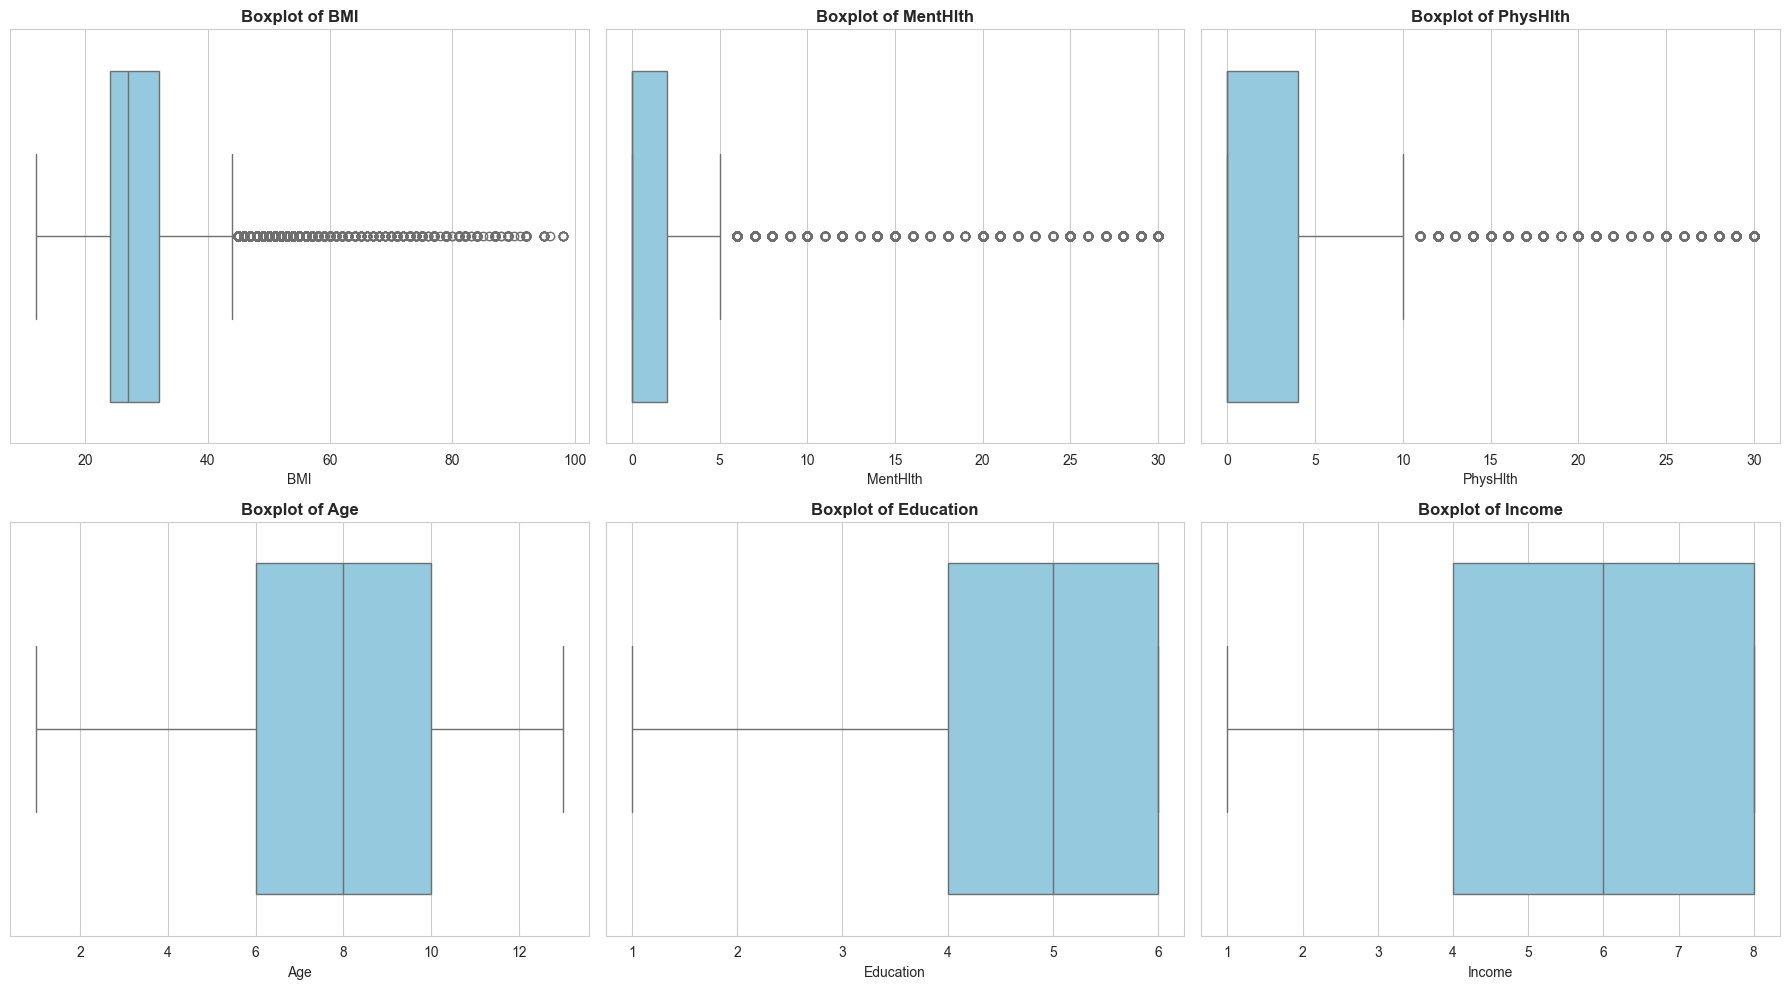

In [17]:
# Individual boxplots for continuous features
continuous_features = ['BMI', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, feature in enumerate(continuous_features):
    sns.boxplot(x=df_binary[feature], ax=axes[idx], color='skyblue')
    axes[idx].set_title(f'Boxplot of {feature}', fontweight='bold')
    axes[idx].set_xlabel(feature)
    
plt.tight_layout()
plt.show()

### Lifestyle Factors Analysis

Examining the impact of lifestyle choices on diabetes risk.

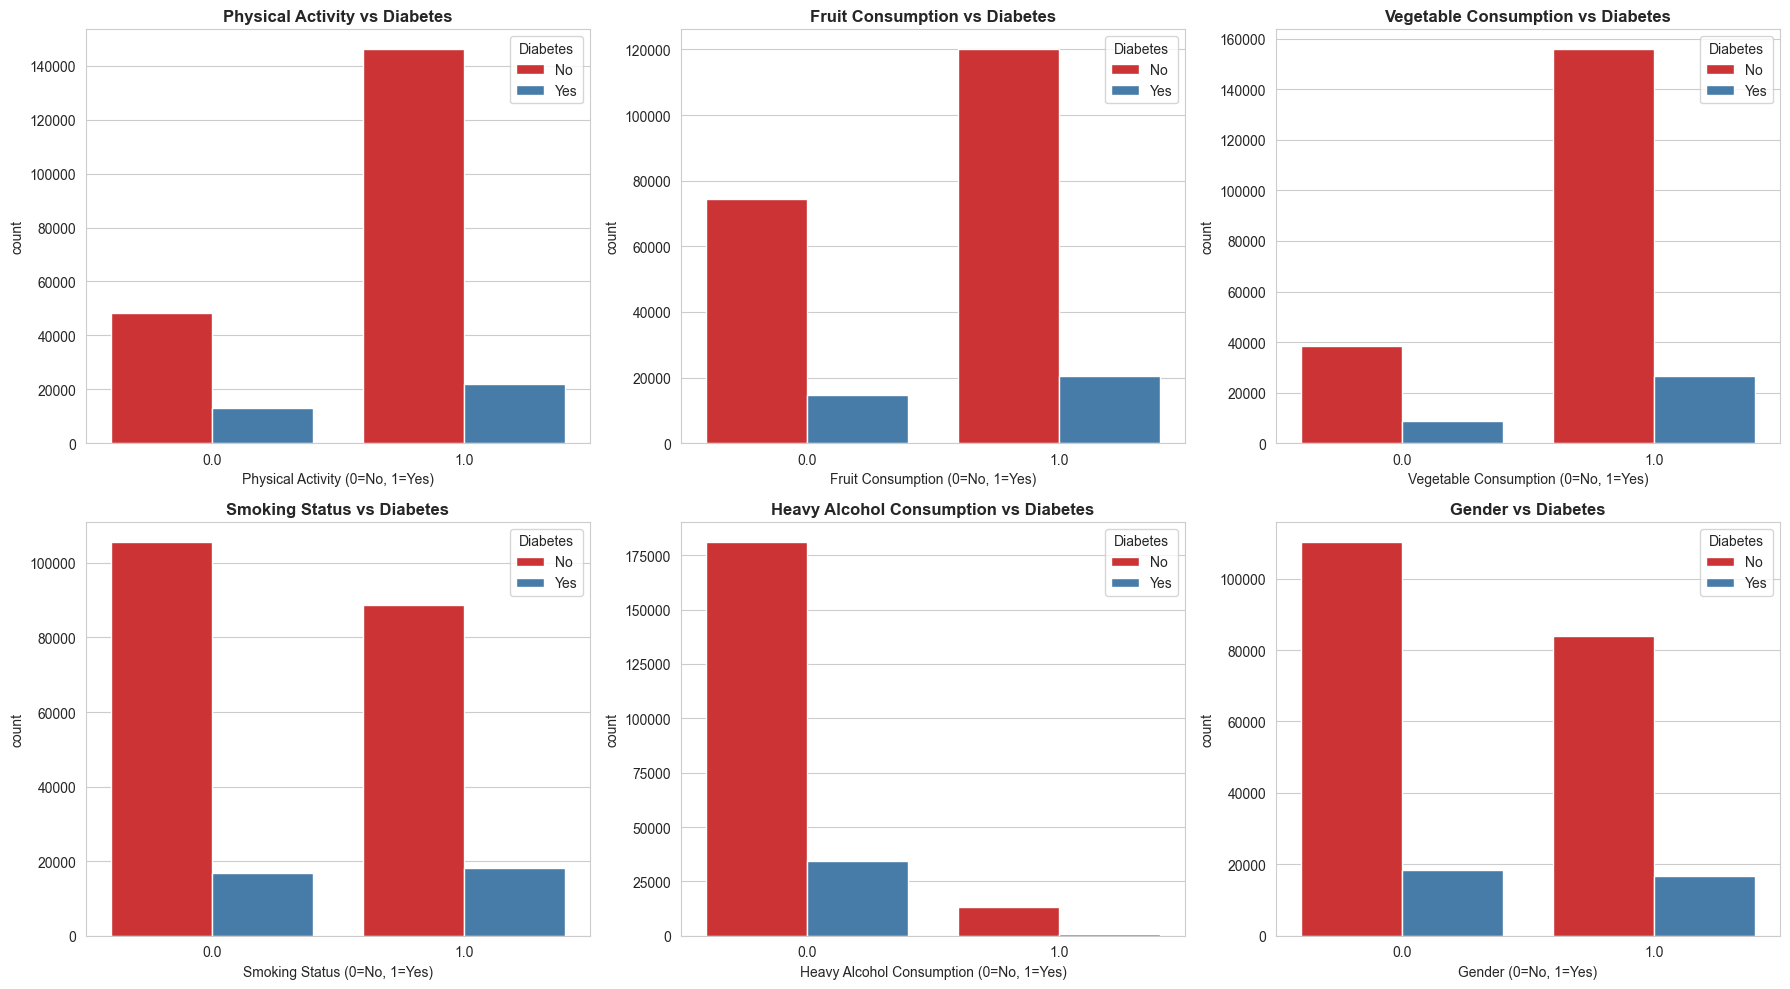

In [18]:
# Analyzing lifestyle factors
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

lifestyle_factors = [
    ('PhysActivity', 'Physical Activity'),
    ('Fruits', 'Fruit Consumption'),
    ('Veggies', 'Vegetable Consumption'),
    ('Smoker', 'Smoking Status'),
    ('HvyAlcoholConsump', 'Heavy Alcohol Consumption'),
    ('Sex', 'Gender')
]

for idx, (feature, title) in enumerate(lifestyle_factors):
    row, col = idx // 3, idx % 3
    sns.countplot(x=feature, hue='Diabetes_binary', data=df_binary, ax=axes[row, col], palette='Set1')
    axes[row, col].set_title(f'{title} vs Diabetes', fontweight='bold')
    axes[row, col].set_xlabel(f'{title} (0=No, 1=Yes)')
    axes[row, col].legend(title='Diabetes', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()

# Data Preprocessing

Preparing the data for machine learning by Data Type conversion, handling outliers, scaling features, and addressing class imbalance.

### Data Type Conversion

Converting all features to integer type for consistency. All features in this dataset are naturally integer values (binary, categorical, or counts).

In [19]:
# Convert all columns to integer type
for col in df_binary.columns:
    df_binary[col] = df_binary[col].astype(int)


### Outlier Analysis and Handling

We'll use a sophisticated approach:
1. **Test for normality** using Shapiro-Wilk test and skewness
2. **Normal distribution**: Apply Z-score method (3σ rule)
3. **Skewed distribution**: Apply IQR method (1.5 × IQR rule)
4. **Visualize before/after** distributions and boxplots
5. **Configurable option**: Choose between trimming (remove) or capping (clip) outliers

In [20]:
# Configuration: Choose outlier handling method ('cap' or 'trim')
OUTLIER_METHOD = 'cap'


In [21]:
from scipy import stats

# Identify features with potential outliers
features_to_analyze = ['BMI', 'MentHlth', 'PhysHlth']

# Analyze distribution characteristics
distribution_info = {}

for feature in features_to_analyze:
    skewness = df_binary[feature].skew()
    
    # Shapiro-Wilk test for normality
    sample_size = min(5000, len(df_binary))
    sample = df_binary[feature].sample(n=sample_size, random_state=42)
    shapiro_stat, shapiro_p = stats.shapiro(sample)
    
    # Determine distribution type
    is_normal = (shapiro_p > 0.05) and (abs(skewness) < 0.5)
    
    distribution_info[feature] = {
        'skewness': skewness,
        'is_normal': is_normal,
        'method': 'Z-Score (3σ)' if is_normal else 'IQR (1.5×IQR)'
    }
    
    print(f"{feature}: {distribution_info[feature]['method']}, Skewness: {skewness:.4f}")


BMI: IQR (1.5×IQR), Skewness: 2.0635
MentHlth: IQR (1.5×IQR), Skewness: 2.5445
PhysHlth: IQR (1.5×IQR), Skewness: 2.0441


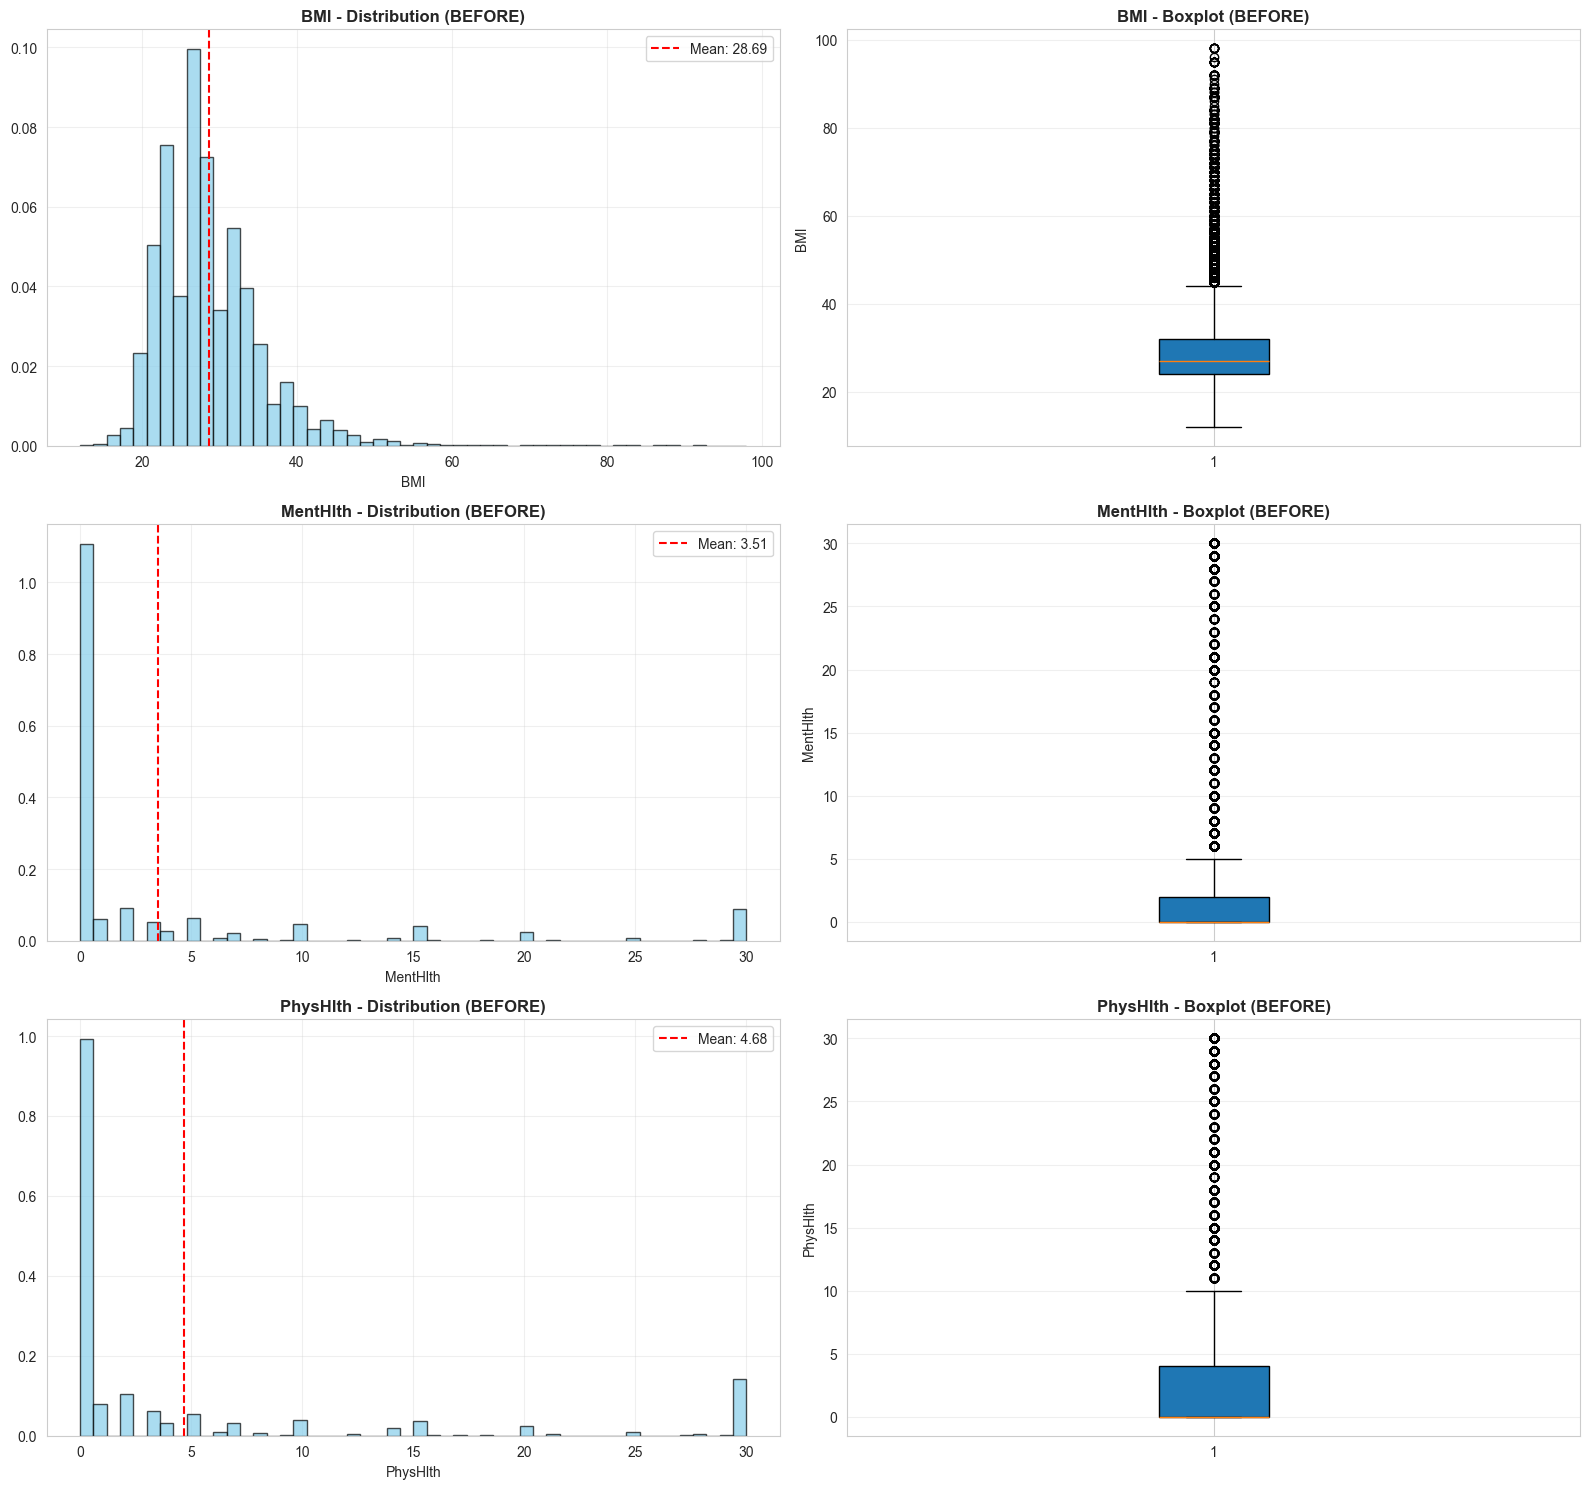

In [22]:
# Visualize BEFORE outlier handling
fig, axes = plt.subplots(len(features_to_analyze), 2, figsize=(16, 5*len(features_to_analyze)))
df_before = df_binary.copy()

for idx, feature in enumerate(features_to_analyze):
    # Distribution plot
    axes[idx, 0].hist(df_binary[feature], bins=50, color='skyblue', edgecolor='black', alpha=0.7, density=True)
    axes[idx, 0].set_title(f'{feature} - Distribution (BEFORE)', fontweight='bold')
    axes[idx, 0].set_xlabel(feature)
    axes[idx, 0].axvline(df_binary[feature].mean(), color='red', linestyle='--', label=f'Mean: {df_binary[feature].mean():.2f}')
    axes[idx, 0].legend()
    axes[idx, 0].grid(alpha=0.3)
    
    # Box plot
    axes[idx, 1].boxplot(df_binary[feature], vert=True, patch_artist=True)
    axes[idx, 1].set_title(f'{feature} - Boxplot (BEFORE)', fontweight='bold')
    axes[idx, 1].set_ylabel(feature)
    axes[idx, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


In [23]:
# Apply outlier handling
original_shape = df_binary.shape
outlier_summary = {}

for feature in features_to_analyze:
    if distribution_info[feature]['is_normal']:
        # Z-Score Method (3 standard deviations)
        mean = df_binary[feature].mean()
        std = df_binary[feature].std()
        lower_bound = mean - 3 * std
        upper_bound = mean + 3 * std
    else:
        # IQR Method (1.5 × IQR)
        Q1 = df_binary[feature].quantile(0.25)
        Q3 = df_binary[feature].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
    
    # Identify outliers
    outliers_mask = (df_binary[feature] < lower_bound) | (df_binary[feature] > upper_bound)
    n_outliers = outliers_mask.sum()
    
    # Apply handling method
    if OUTLIER_METHOD == 'cap':
        df_binary[feature] = df_binary[feature].clip(lower=lower_bound, upper=upper_bound)
    elif OUTLIER_METHOD == 'trim':
        df_binary = df_binary[~outliers_mask].copy()
    
    outlier_summary[feature] = {
        'method': distribution_info[feature]['method'],
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'n_outliers': n_outliers,
        'handling': OUTLIER_METHOD
    }
    
    print(f"{feature}: {n_outliers} outliers ({n_outliers/len(df_binary)*100:.2f}%) - {OUTLIER_METHOD}ped")

print(f"\nFinal records: {df_binary.shape[0]:,}")


BMI: 5638 outliers (2.46%) - capped
MentHlth: 36162 outliers (15.76%) - capped
PhysHlth: 34346 outliers (14.97%) - capped

Final records: 229,474


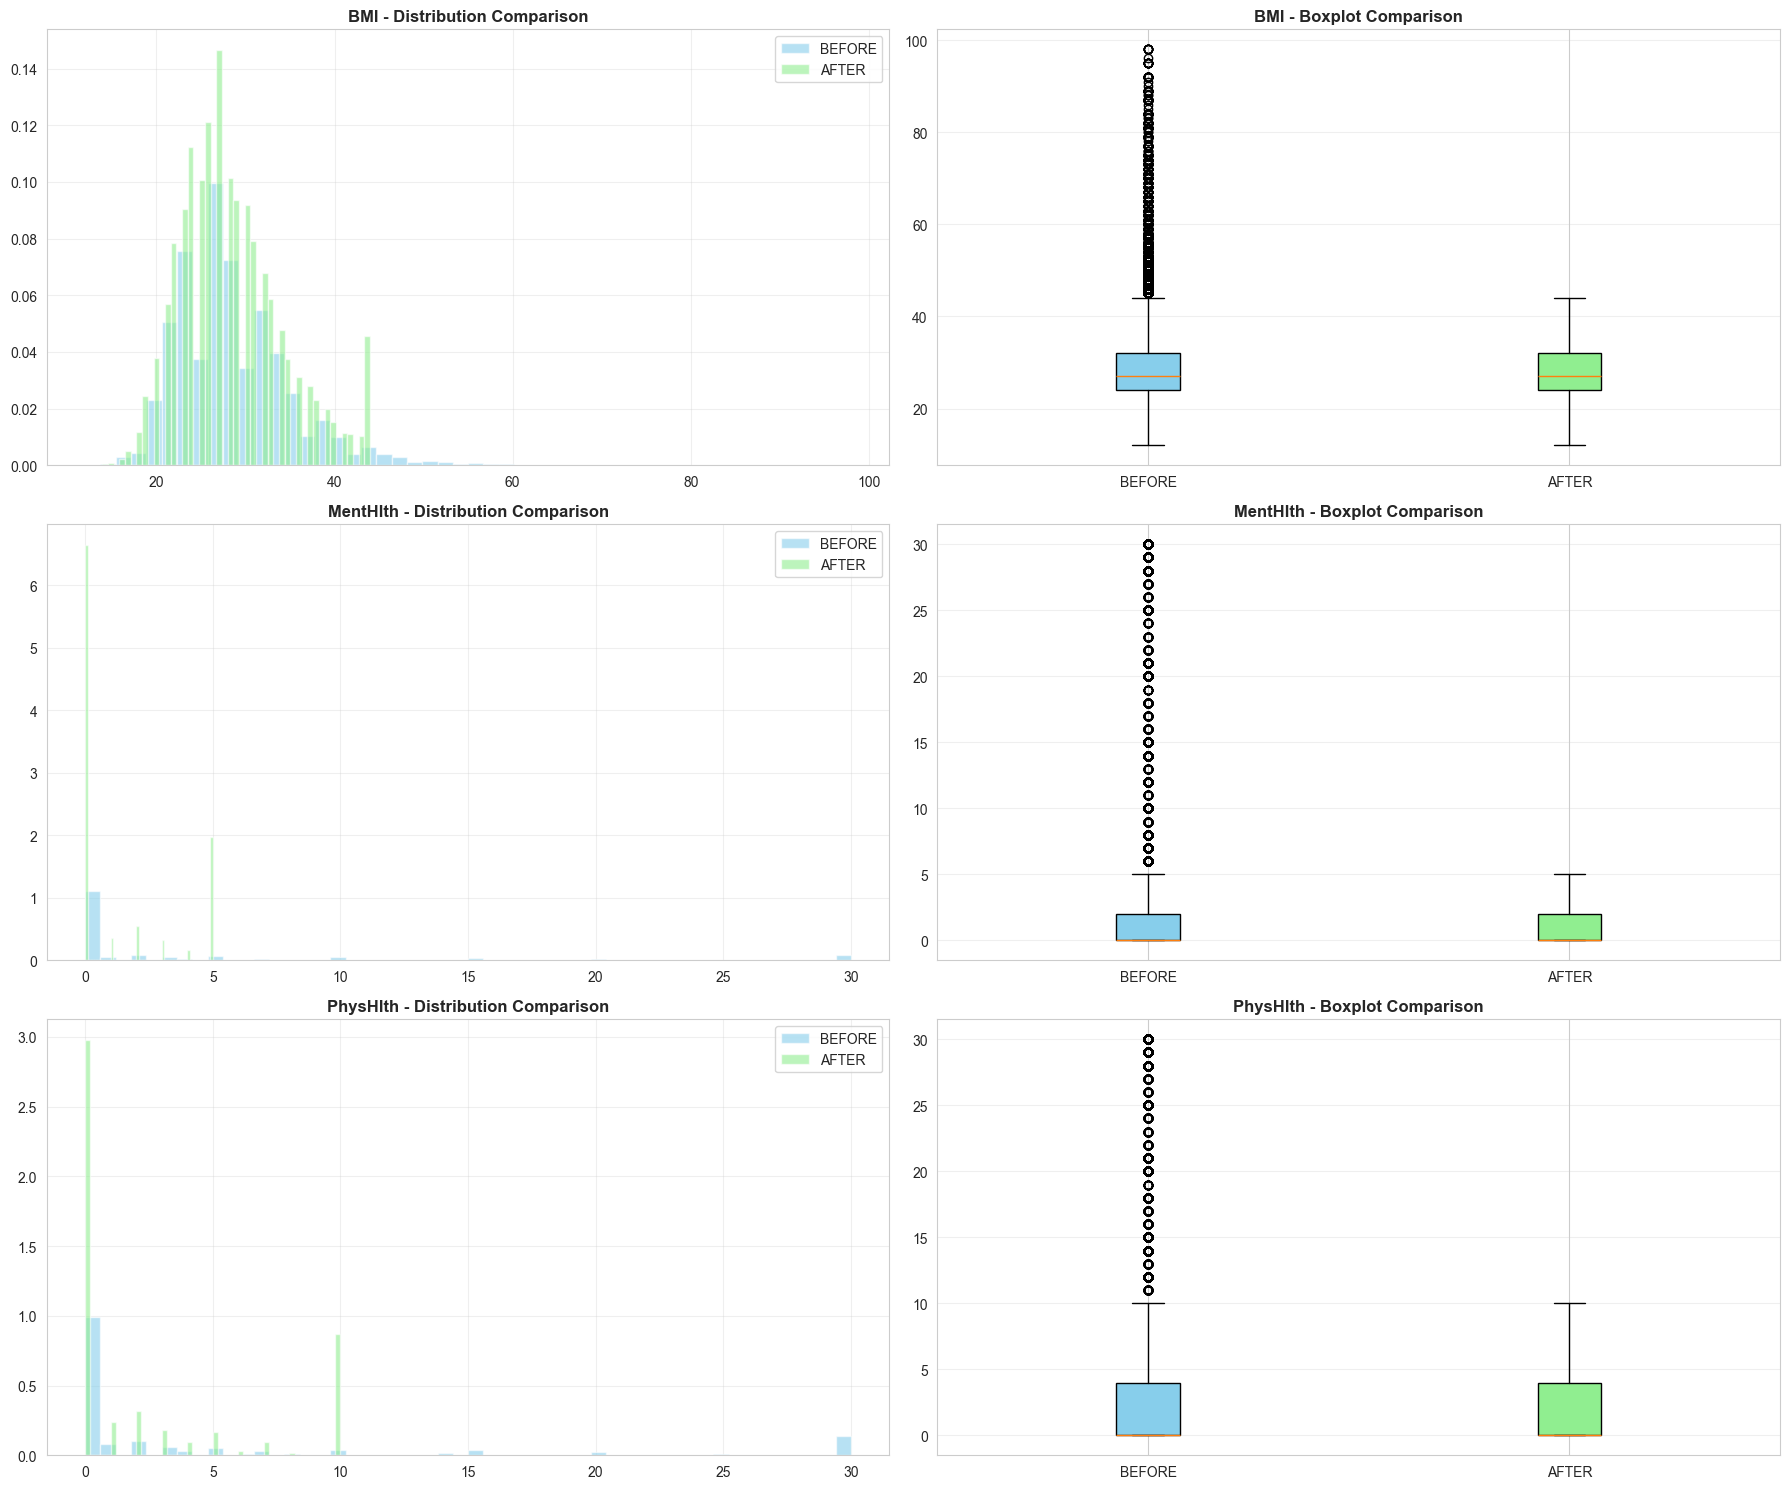

In [24]:
# Compare BEFORE vs AFTER
fig, axes = plt.subplots(len(features_to_analyze), 2, figsize=(18, 5*len(features_to_analyze)))

for idx, feature in enumerate(features_to_analyze):
    # Histogram comparison
    axes[idx, 0].hist(df_before[feature], bins=50, color='skyblue', alpha=0.6, label='BEFORE', density=True)
    axes[idx, 0].hist(df_binary[feature], bins=50, color='lightgreen', alpha=0.6, label='AFTER', density=True)
    axes[idx, 0].set_title(f'{feature} - Distribution Comparison', fontweight='bold')
    axes[idx, 0].legend()
    axes[idx, 0].grid(alpha=0.3)
    
    # Box plot comparison
    bp_data = [df_before[feature], df_binary[feature]]
    bp = axes[idx, 1].boxplot(bp_data, labels=['BEFORE', 'AFTER'], patch_artist=True)
    bp['boxes'][0].set_facecolor('skyblue')
    bp['boxes'][1].set_facecolor('lightgreen')
    axes[idx, 1].set_title(f'{feature} - Boxplot Comparison', fontweight='bold')
    axes[idx, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


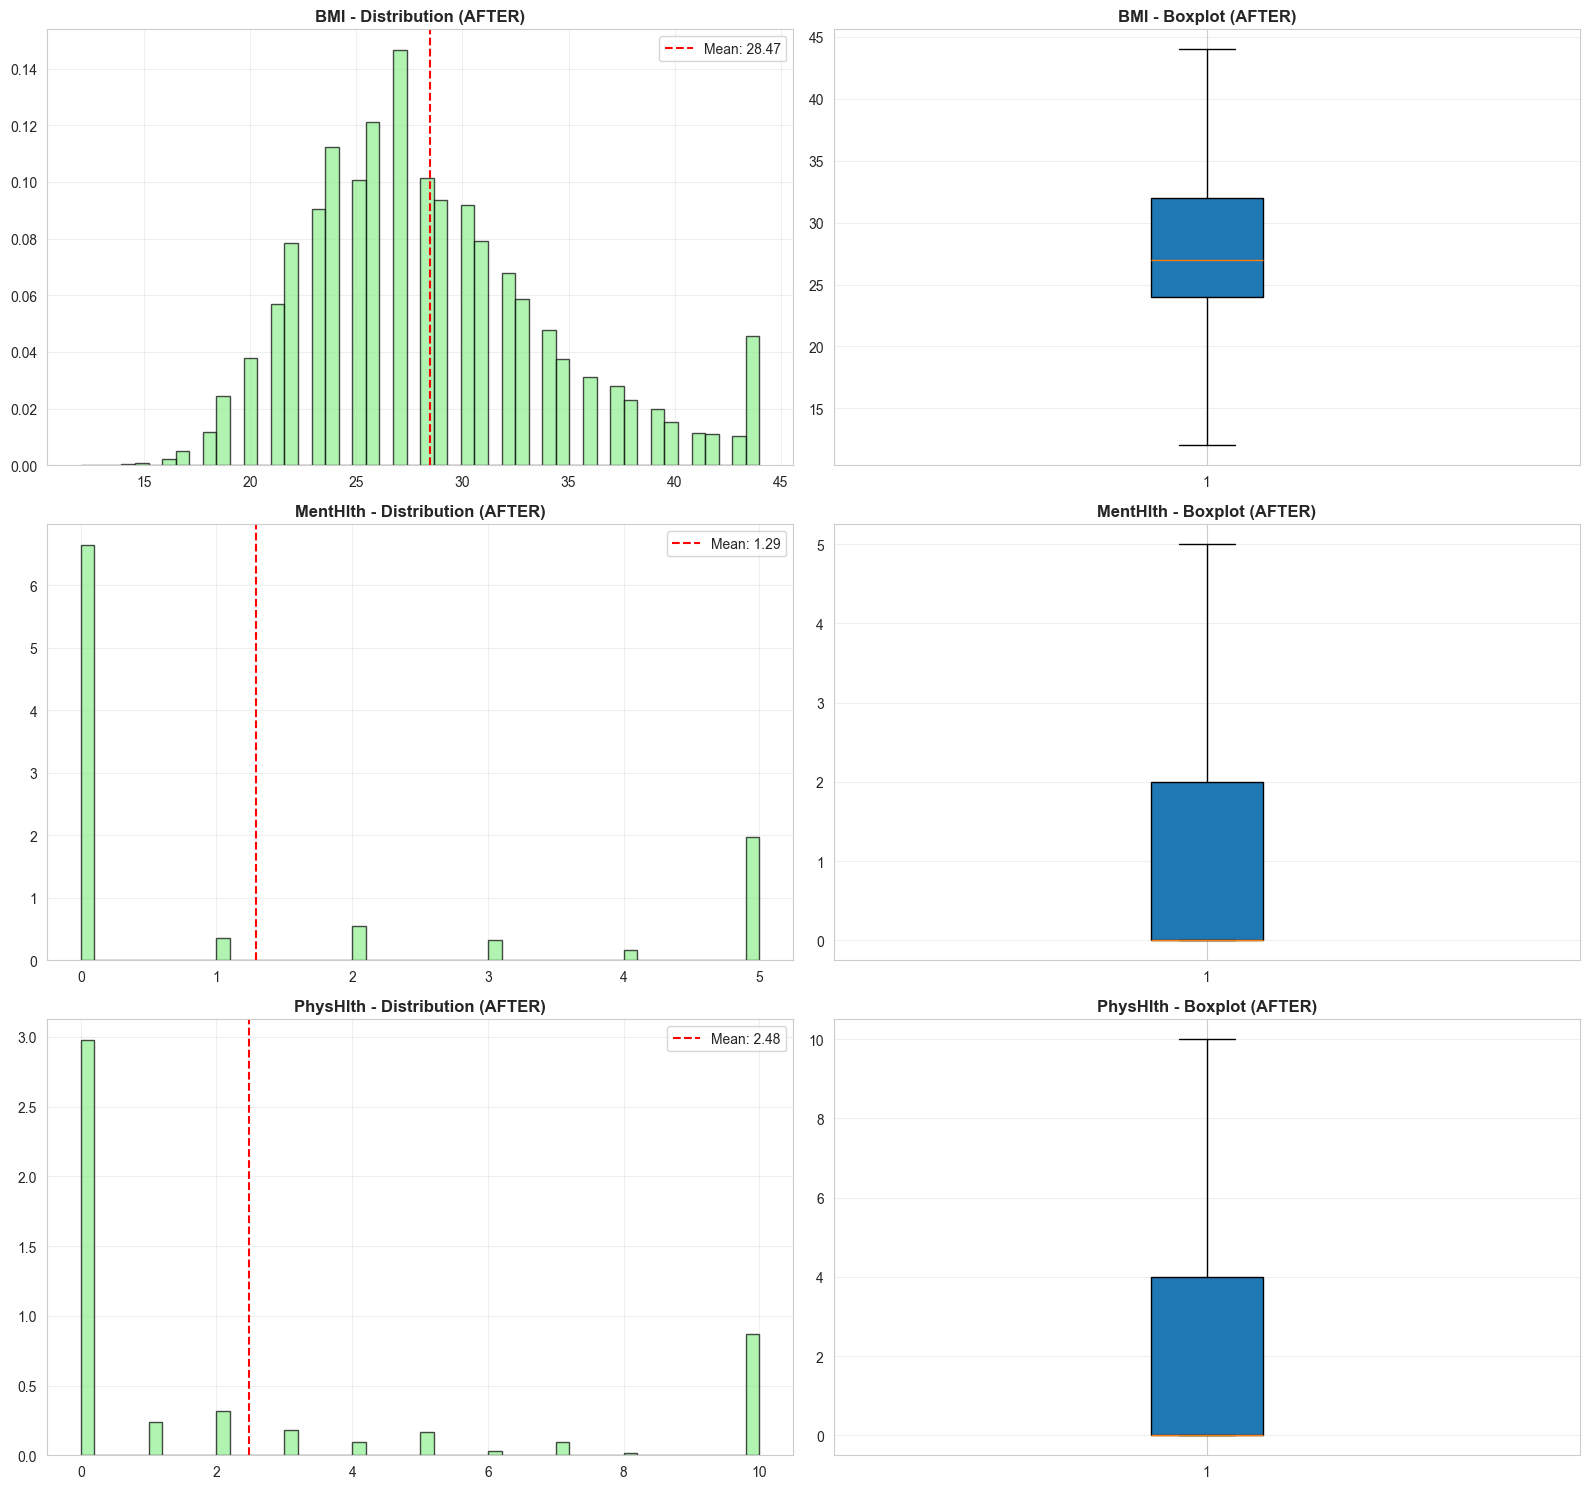

In [25]:
# Visualize AFTER outlier handling
fig, axes = plt.subplots(len(features_to_analyze), 2, figsize=(16, 5*len(features_to_analyze)))

for idx, feature in enumerate(features_to_analyze):
    # Distribution plot
    axes[idx, 0].hist(df_binary[feature], bins=50, color='lightgreen', edgecolor='black', alpha=0.7, density=True)
    axes[idx, 0].set_title(f'{feature} - Distribution (AFTER)', fontweight='bold')
    axes[idx, 0].axvline(df_binary[feature].mean(), color='red', linestyle='--', label=f'Mean: {df_binary[feature].mean():.2f}')
    axes[idx, 0].legend()
    axes[idx, 0].grid(alpha=0.3)
    
    # Box plot
    axes[idx, 1].boxplot(df_binary[feature], vert=True, patch_artist=True)
    axes[idx, 1].set_title(f'{feature} - Boxplot (AFTER)', fontweight='bold')
    axes[idx, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


### Encoding Categorical Features

Creating one-hot encoded versions of ordinal/categorical features for models that benefit from this representation (neural networks, linear models, etc.).

In [26]:
# Features to encode
features_to_encode = {
    'Age': 'Age categories (1-13)',
    'Education': 'Education levels (1-6)', 
    'Income': 'Income levels (1-8)',
    'GenHlth': 'General health rating (1-5)',
}

print("Features for One-Hot Encoding:")
for feature, desc in features_to_encode.items():
    print(f"  {feature}: {df_binary[feature].nunique()} categories")


Features for One-Hot Encoding:
  Age: 13 categories
  Education: 6 categories
  Income: 8 categories
  GenHlth: 5 categories


In [27]:
# Apply one-hot encoding
df_encoded = df_binary.copy()

for feature in features_to_encode.keys():
    dummies = pd.get_dummies(df_encoded[feature], prefix=feature, drop_first=False, dtype=int)
    df_encoded = pd.concat([df_encoded, dummies], axis=1)
    df_encoded.drop(feature, axis=1, inplace=True)
    print(f"{feature}: {len(dummies.columns)} columns created")

print(f"\nEncoded features: {df_encoded.shape[1]}")
df_encoded.head()


Age: 13 columns created
Education: 6 columns created
Income: 8 columns created
GenHlth: 5 columns created

Encoded features: 50


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,Income_4,Income_5,Income_6,Income_7,Income_8,GenHlth_1,GenHlth_2,GenHlth_3,GenHlth_4,GenHlth_5
0,0,1,1,1,40,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,25,1,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
2,0,1,1,1,28,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
3,0,1,0,1,27,0,0,0,1,1,...,0,0,1,0,0,0,1,0,0,0
4,0,1,1,1,24,0,0,0,1,1,...,1,0,0,0,0,0,1,0,0,0


In [28]:
# Compare original vs encoded
comparison_data = {
    'Metric': ['Total Features', 'Memory (MB)', 'Samples'],
    'Original': [
        df_binary.shape[1],
        f"{df_binary.memory_usage(deep=True).sum() / 1024**2:.2f}",
        df_binary.shape[0]
    ],
    'Encoded': [
        df_encoded.shape[1],
        f"{df_encoded.memory_usage(deep=True).sum() / 1024**2:.2f}",
        df_encoded.shape[0]
    ]
}

pd.DataFrame(comparison_data)


,Metric,Original,Encoded
0,Total Features,22,50
1,Memory (MB),40.27,89.29
2,Samples,229474,229474


## Data Splitting and Scaling

Preparing the data for machine learning by splitting into train/test sets, handling class imbalance, and scaling features.

### Separate Features and Target

In [29]:
# Separate features (X) and target (Y)
X = df_binary.drop("Diabetes_binary", axis=1)
Y = df_binary["Diabetes_binary"]

print(f"Features shape: {X.shape}")
print(f"Target shape: {Y.shape}")

Features shape: (229474, 21)
Target shape: (229474,)


### Check Class Imbalance

In [30]:
# Check class distribution
print("Class distribution before handling imbalance:")
print(Y.value_counts())
print(f"\nImbalance ratio: {Y.value_counts()[0] / Y.value_counts()[1]:.2f}:1")

Class distribution before handling imbalance:
Diabetes_binary
0    194377
1     35097
Name: count, dtype: int64

Imbalance ratio: 5.54:1


### Handle Class Imbalance using NearMiss

Using NearMiss undersampling to balance the dataset by selecting representative samples from the majority class.

In [31]:
from imblearn.under_sampling import NearMiss

# Apply NearMiss undersampling
nm = NearMiss(version=1, n_neighbors=10)
x_sm, y_sm = nm.fit_resample(X, Y)

print(f"Resampled data shape: {x_sm.shape}")
print(f"Resampled target shape: {y_sm.shape}")
print(f"\nClass distribution after NearMiss:")
print(y_sm.value_counts())

Resampled data shape: (70194, 21)
Resampled target shape: (70194,)

Class distribution after NearMiss:
Diabetes_binary
0    35097
1    35097
Name: count, dtype: int64


### Train-Test Split

Splitting the balanced dataset into training (70%) and testing (30%) sets.

In [32]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(x_sm, y_sm, test_size=0.3, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print(f"\nTraining set class distribution:")
print(Y_train.value_counts())
print(f"\nTesting set class distribution:")
print(Y_test.value_counts())

Training set size: 49135 samples
Testing set size: 21059 samples

Training set class distribution:
Diabetes_binary
0    24629
1    24506
Name: count, dtype: int64

Testing set class distribution:
Diabetes_binary
1    10591
0    10468
Name: count, dtype: int64


### Feature Scaling

Standardizing features using StandardScaler to ensure all features have mean=0 and standard deviation=1, which improves model performance.

In [33]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform both train and test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training data scaled: {X_train_scaled.shape}")
print(f"Testing data scaled: {X_test_scaled.shape}")
print(f"\nTraining data - Mean: {X_train_scaled.mean():.6f}, Std: {X_train_scaled.std():.6f}")
print(f"Testing data - Mean: {X_test_scaled.mean():.6f}, Std: {X_test_scaled.std():.6f}")

Training data scaled: (49135, 21)
Testing data scaled: (21059, 21)

Training data - Mean: -0.000000, Std: 1.000000
Testing data - Mean: 0.002523, Std: 1.001128


### Save Preprocessed Datasets for All Models

We save **two versions** of the preprocessed data, optimized for different model families:

| Dataset Version | Encoding | Best For |
|---|---|---|
| **Ordinal + Scaled** | Original integer features | Decision Tree, Random Forest, XGBoost, AdaBoost, Gradient Boost, LGBM |
| **One-Hot Encoded + Scaled** | Categorical features one-hot encoded | Logistic Regression, KNN, SVM |

Both versions go through: Duplicate removal → Outlier handling → NearMiss balancing → 70/30 split → StandardScaler

In [34]:
import os
from imblearn.under_sampling import NearMiss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

os.makedirs('./data/preprocessed', exist_ok=True)

# ============================================================
# VERSION 1: Ordinal + Scaled (for tree-based models)
# Best for: Decision Tree, Random Forest, XGBoost, AdaBoost, 
#           Gradient Boost, LGBM
# ============================================================
X_train_ord_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_ord_df = pd.DataFrame(X_test_scaled, columns=X.columns)

train_ordinal = X_train_ord_df.copy()
train_ordinal['Diabetes_binary'] = Y_train.values
test_ordinal = X_test_ord_df.copy()
test_ordinal['Diabetes_binary'] = Y_test.values

train_ordinal.to_csv('./data/preprocessed/6_diabetes_ordinal_train.csv', index=False)
test_ordinal.to_csv('./data/preprocessed/6_diabetes_ordinal_test.csv', index=False)

print("=" * 65)
print("VERSION 1: Ordinal + Scaled (Tree-based models)")
print("=" * 65)
print(f"  Models: Decision Tree, Random Forest, XGBoost, AdaBoost,")
print(f"          Gradient Boost, LGBM")
print(f"  Train: {train_ordinal.shape[0]} samples x {train_ordinal.shape[1]} features")
print(f"  Test:  {test_ordinal.shape[0]} samples x {test_ordinal.shape[1]} features")
print(f"  Files: 6_diabetes_ordinal_train.csv, 6_diabetes_ordinal_test.csv")

# ============================================================
# VERSION 2: One-Hot Encoded + Scaled (for linear/distance models)
# Best for: Logistic Regression, KNN, SVM
# ============================================================
X_enc = df_encoded.drop("Diabetes_binary", axis=1)
Y_enc = df_encoded["Diabetes_binary"]

# Apply NearMiss undersampling on encoded data
nm_enc = NearMiss(version=1, n_neighbors=10)
X_enc_sm, Y_enc_sm = nm_enc.fit_resample(X_enc, Y_enc)

# Train-Test Split
X_train_enc, X_test_enc, Y_train_enc, Y_test_enc = train_test_split(
    X_enc_sm, Y_enc_sm, test_size=0.3, random_state=42
)

# Feature Scaling
scaler_enc = StandardScaler()
X_train_enc_scaled = scaler_enc.fit_transform(X_train_enc)
X_test_enc_scaled = scaler_enc.transform(X_test_enc)

X_train_enc_df = pd.DataFrame(X_train_enc_scaled, columns=X_enc.columns)
X_test_enc_df = pd.DataFrame(X_test_enc_scaled, columns=X_enc.columns)

train_encoded = X_train_enc_df.copy()
train_encoded['Diabetes_binary'] = Y_train_enc.values
test_encoded = X_test_enc_df.copy()
test_encoded['Diabetes_binary'] = Y_test_enc.values

train_encoded.to_csv('./data/preprocessed/6_diabetes_encoded_train.csv', index=False)
test_encoded.to_csv('./data/preprocessed/6_diabetes_encoded_test.csv', index=False)

print(f"\n{'=' * 65}")
print("VERSION 2: One-Hot Encoded + Scaled (Linear/Distance models)")
print("=" * 65)
print(f"  Models: Logistic Regression, KNN, SVM")
print(f"  Train: {train_encoded.shape[0]} samples x {train_encoded.shape[1]} features")
print(f"  Test:  {test_encoded.shape[0]} samples x {test_encoded.shape[1]} features")
print(f"  Files: 6_diabetes_encoded_train.csv, 6_diabetes_encoded_test.csv")

# ============================================================
# SUMMARY TABLE
# ============================================================
print(f"\n{'=' * 65}")
print("MODEL → DATASET MAPPING")
print("=" * 65)
model_mapping = {
    'Logistic Regression': 'One-Hot Encoded (6_diabetes_encoded_*)',
    'KNN':                 'One-Hot Encoded (6_diabetes_encoded_*)',
    'SVM':                 'One-Hot Encoded (6_diabetes_encoded_*)',
    'Decision Tree':       'Ordinal (6_diabetes_ordinal_*)',
    'Random Forest':       'Ordinal (6_diabetes_ordinal_*)',
    'XGBoost':             'Ordinal (6_diabetes_ordinal_*)',
    'AdaBoost':            'Ordinal (6_diabetes_ordinal_*)',
    'Gradient Boost':      'Ordinal (6_diabetes_ordinal_*)',
    'LGBM':                'Ordinal (6_diabetes_ordinal_*)',
}
for model, dataset in model_mapping.items():
    print(f"  {model:<22s} → {dataset}")
print("=" * 65)
print("\n✓ All preprocessed datasets saved to ./data/preprocessed/")

VERSION 1: Ordinal + Scaled (Tree-based models)
  Models: Decision Tree, Random Forest, XGBoost, AdaBoost,
          Gradient Boost, LGBM
  Train: 49135 samples x 22 features
  Test:  21059 samples x 22 features
  Files: 6_diabetes_ordinal_train.csv, 6_diabetes_ordinal_test.csv

VERSION 2: One-Hot Encoded + Scaled (Linear/Distance models)
  Models: Logistic Regression, KNN, SVM
  Train: 49135 samples x 50 features
  Test:  21059 samples x 50 features
  Files: 6_diabetes_encoded_train.csv, 6_diabetes_encoded_test.csv

MODEL → DATASET MAPPING
  Logistic Regression    → One-Hot Encoded (6_diabetes_encoded_*)
  KNN                    → One-Hot Encoded (6_diabetes_encoded_*)
  SVM                    → One-Hot Encoded (6_diabetes_encoded_*)
  Decision Tree          → Ordinal (6_diabetes_ordinal_*)
  Random Forest          → Ordinal (6_diabetes_ordinal_*)
  XGBoost                → Ordinal (6_diabetes_ordinal_*)
  AdaBoost               → Ordinal (6_diabetes_ordinal_*)
  Gradient Boost       

### Final Summary

Complete preprocessing pipeline with all steps applied:

In [35]:
print("=" * 65)
print("PREPROCESSING PIPELINE COMPLETE")
print("=" * 65)
print(f"\n1. Original Dataset: 253,680 samples, 22 features")
print(f"2. After Duplicate Removal: {df_binary.shape[0]:,} samples")
print(f"3. After Outlier Handling (BMI, MentHlth, PhysHlth): capped")
print(f"4. After Feature Engineering: {df_binary.shape[1]} ordinal / {df_encoded.shape[1]} encoded features")
print(f"5. After NearMiss Balancing: {x_sm.shape[0]:,} samples (ordinal), {X_enc_sm.shape[0]:,} samples (encoded)")

print(f"\n6. Saved Datasets:")
print(f"   ┌─────────────────────────────────────────────────────────┐")
print(f"   │ Ordinal (tree-based)    │ Train: {train_ordinal.shape[0]:,} │ Test: {test_ordinal.shape[0]:,} │ {train_ordinal.shape[1]} cols │")
print(f"   │ Encoded (linear/dist.)  │ Train: {train_encoded.shape[0]:,} │ Test: {test_encoded.shape[0]:,} │ {train_encoded.shape[1]} cols │")
print(f"   └─────────────────────────────────────────────────────────┘")

print(f"\n7. Scaling: StandardScaler applied to both versions")
print(f"\n✓ Data is ready for all 9 ML models!")
print("=" * 65)

PREPROCESSING PIPELINE COMPLETE

1. Original Dataset: 253,680 samples, 22 features
2. After Duplicate Removal: 229,474 samples
3. After Outlier Handling (BMI, MentHlth, PhysHlth): capped
4. After Feature Engineering: 22 ordinal / 50 encoded features
5. After NearMiss Balancing: 70,194 samples (ordinal), 70,194 samples (encoded)

6. Saved Datasets:
   ┌─────────────────────────────────────────────────────────┐
   │ Ordinal (tree-based)    │ Train: 49,135 │ Test: 21,059 │ 22 cols │
   │ Encoded (linear/dist.)  │ Train: 49,135 │ Test: 21,059 │ 50 cols │
   └─────────────────────────────────────────────────────────┘

7. Scaling: StandardScaler applied to both versions

✓ Data is ready for all 9 ML models!


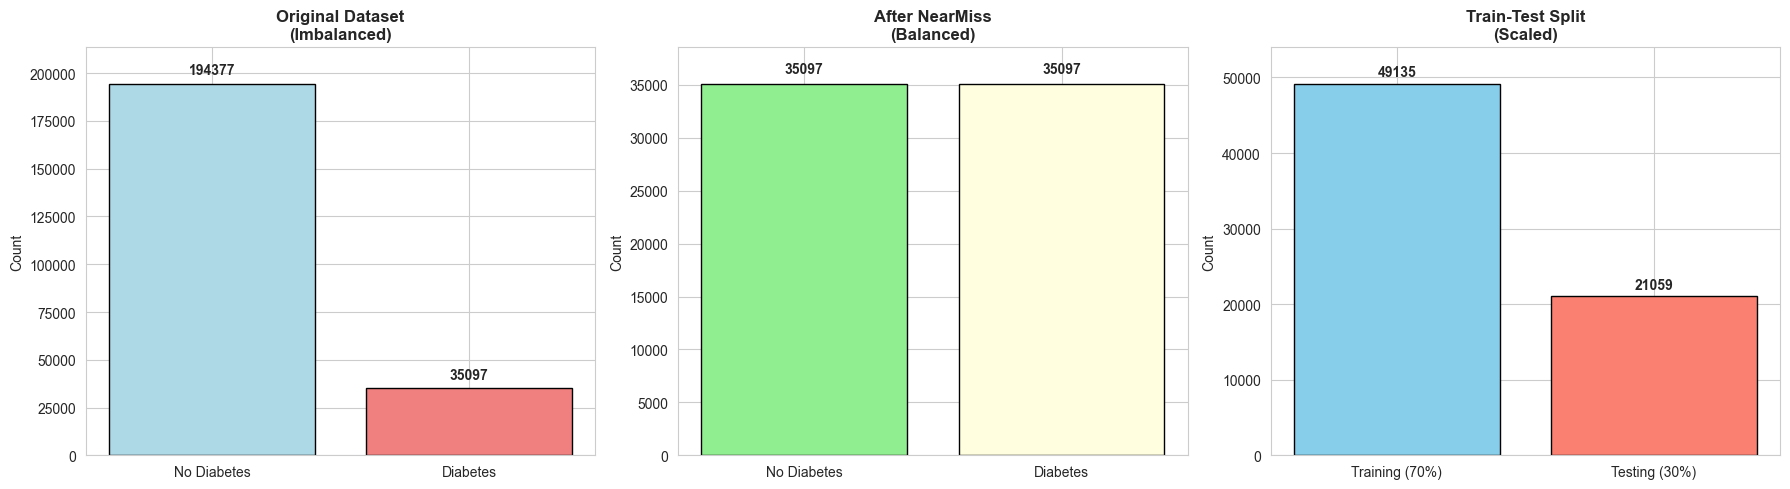

In [36]:
# Visualize the preprocessing pipeline
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original class distribution
axes[0].bar(['No Diabetes', 'Diabetes'], Y.value_counts().values, color=['lightblue', 'lightcoral'], edgecolor='black')
axes[0].set_title('Original Dataset\n(Imbalanced)', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, max(Y.value_counts().values) * 1.1)
for i, v in enumerate(Y.value_counts().values):
    axes[0].text(i, v + 5000, str(v), ha='center', fontweight='bold')

# After balancing
axes[1].bar(['No Diabetes', 'Diabetes'], y_sm.value_counts().values, color=['lightgreen', 'lightyellow'], edgecolor='black')
axes[1].set_title('After NearMiss\n(Balanced)', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Count')
axes[1].set_ylim(0, max(y_sm.value_counts().values) * 1.1)
for i, v in enumerate(y_sm.value_counts().values):
    axes[1].text(i, v + 1000, str(v), ha='center', fontweight='bold')

# Train-Test split
split_data = [X_train_scaled.shape[0], X_test_scaled.shape[0]]
axes[2].bar(['Training (70%)', 'Testing (30%)'], split_data, color=['skyblue', 'salmon'], edgecolor='black')
axes[2].set_title('Train-Test Split\n(Scaled)', fontweight='bold', fontsize=12)
axes[2].set_ylabel('Count')
axes[2].set_ylim(0, max(split_data) * 1.1)
for i, v in enumerate(split_data):
    axes[2].text(i, v + 1000, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()